## AC 20

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.sanos.sanos_tools
%aimport quantdata.sanos.arbfree
%aimport quantdata.sanos.sanos
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig

grid_config     = GridConfig(grid_num_strikes=100)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training ac_state20 version 0.2 group 'sm25_100' for 110000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 400 samples with learning rate 0.0001 and weight decay 0.0001.
01:   Model config: ac_state20@sm25_100 0.2 0.25-smooth nms=20,(-2.00,1.00) state=20@FF(d=2,w=100,a=SELU,b=True) dlv=(0.01,3.00),fvol=(0.01,2.00) sample,mvsq=0.0001
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,19.8,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2,msqv=0.0001
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Instantiating ac_state20 version 0.2 on Env(prec=32,device=cuda,debug=False)... done; this took 0.018s.
00: Found existing recovery checkpoint '/home/hans/.dysanos_grid/sm25_100/ac_state20 15353129.pt'. R

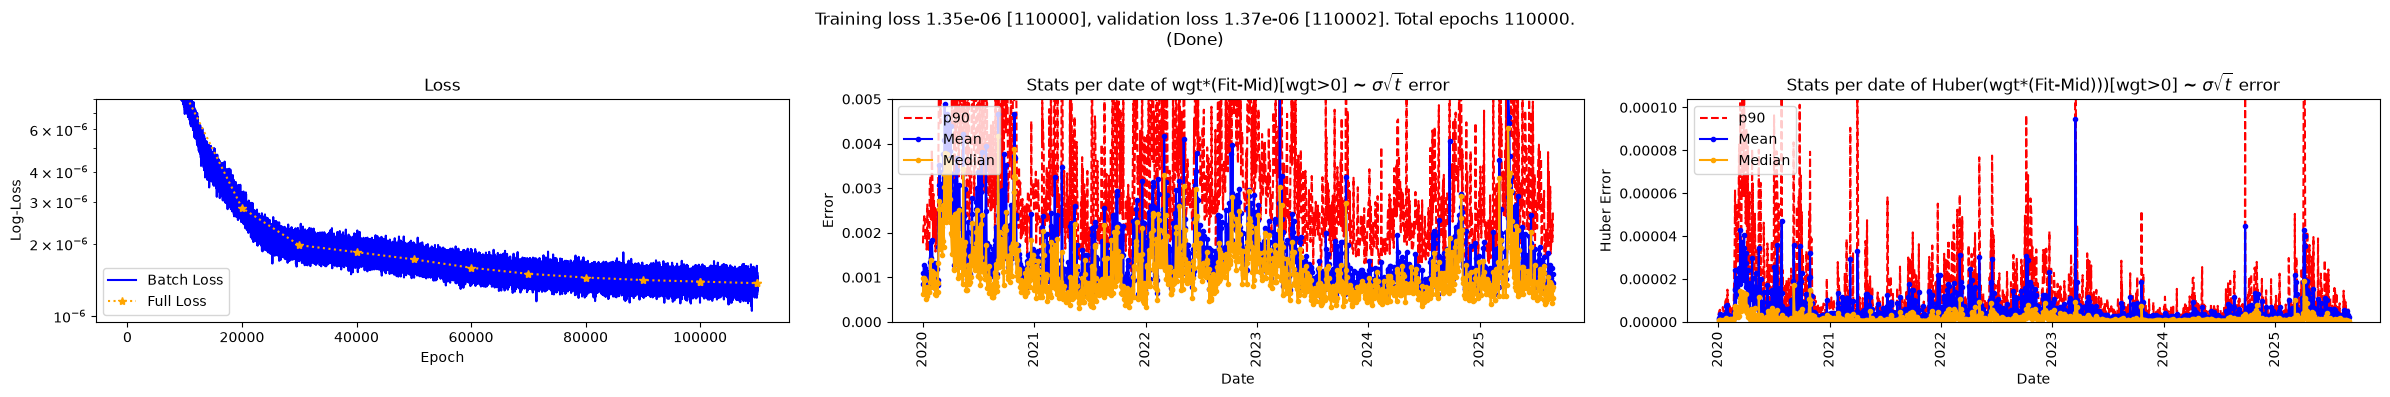

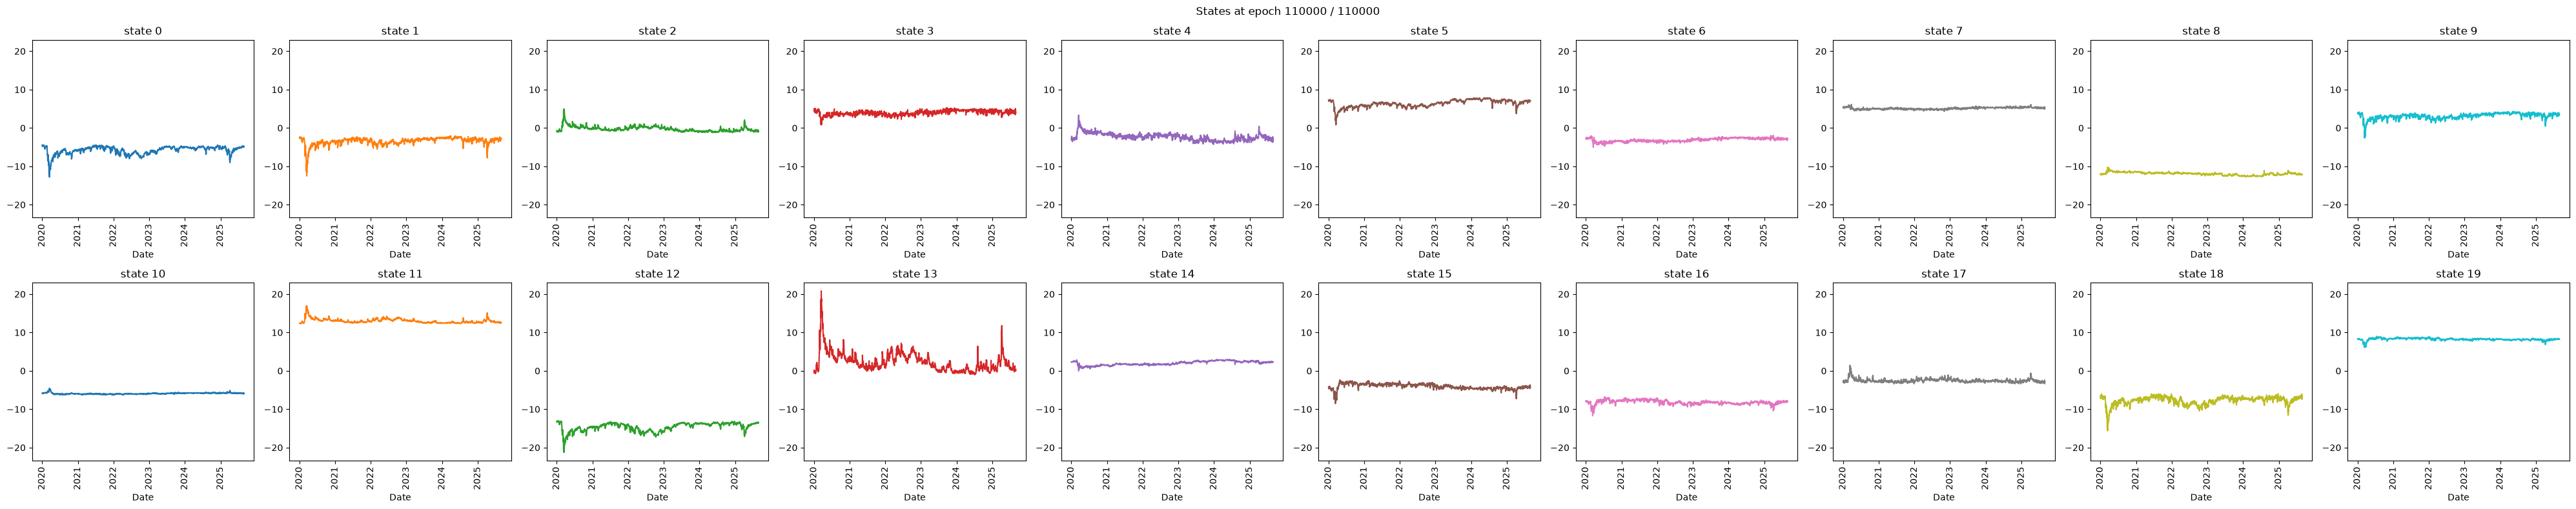

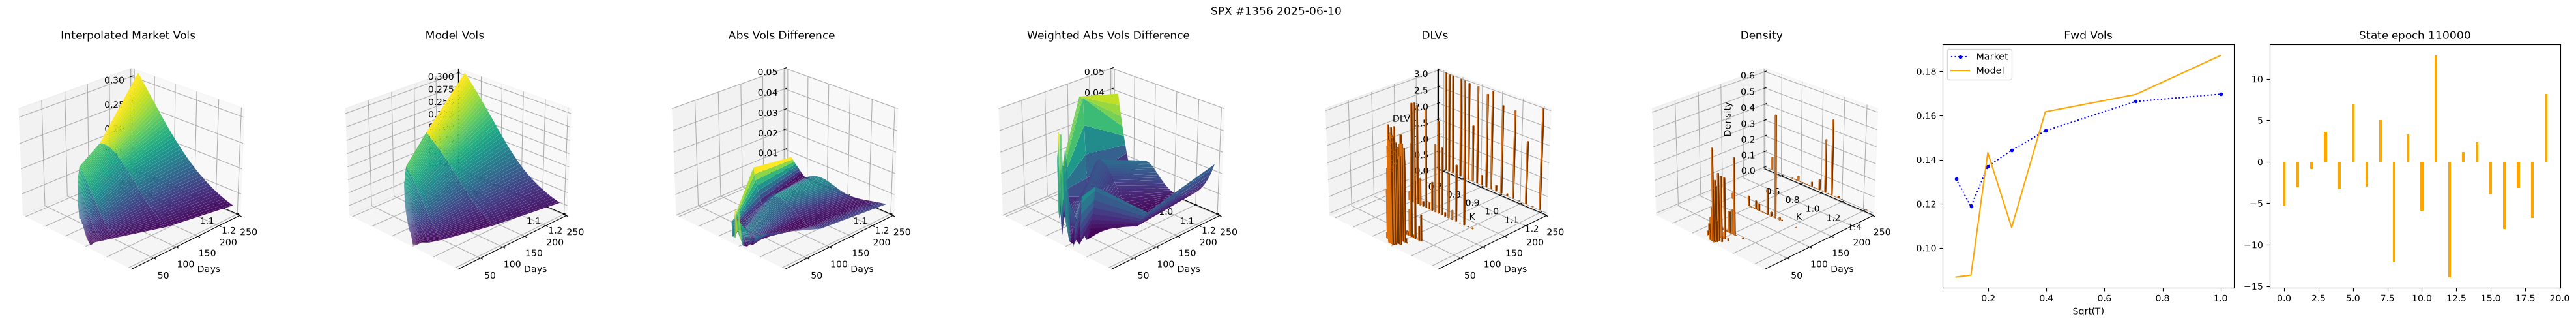

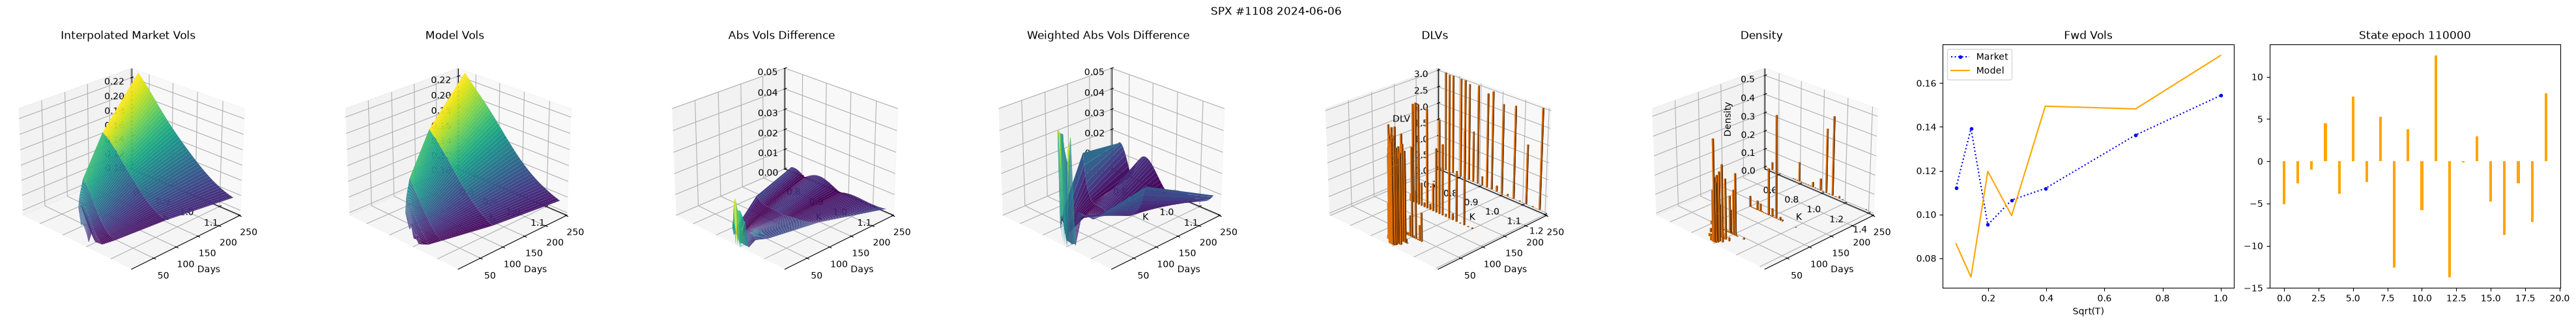

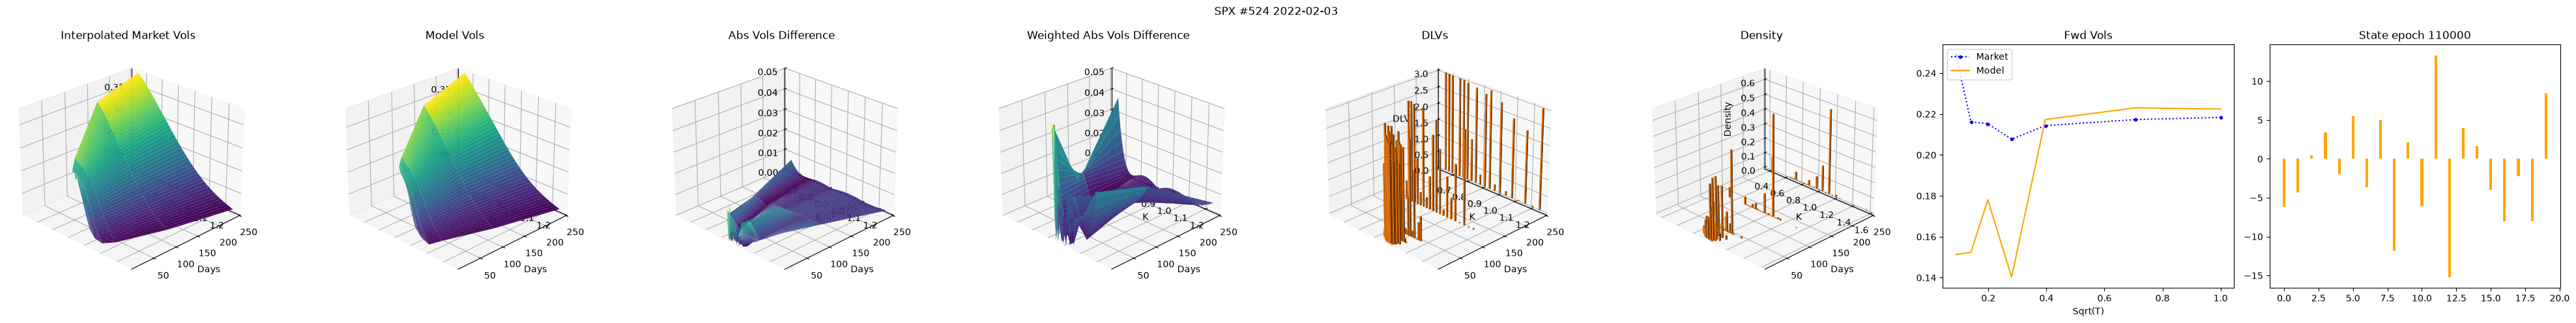

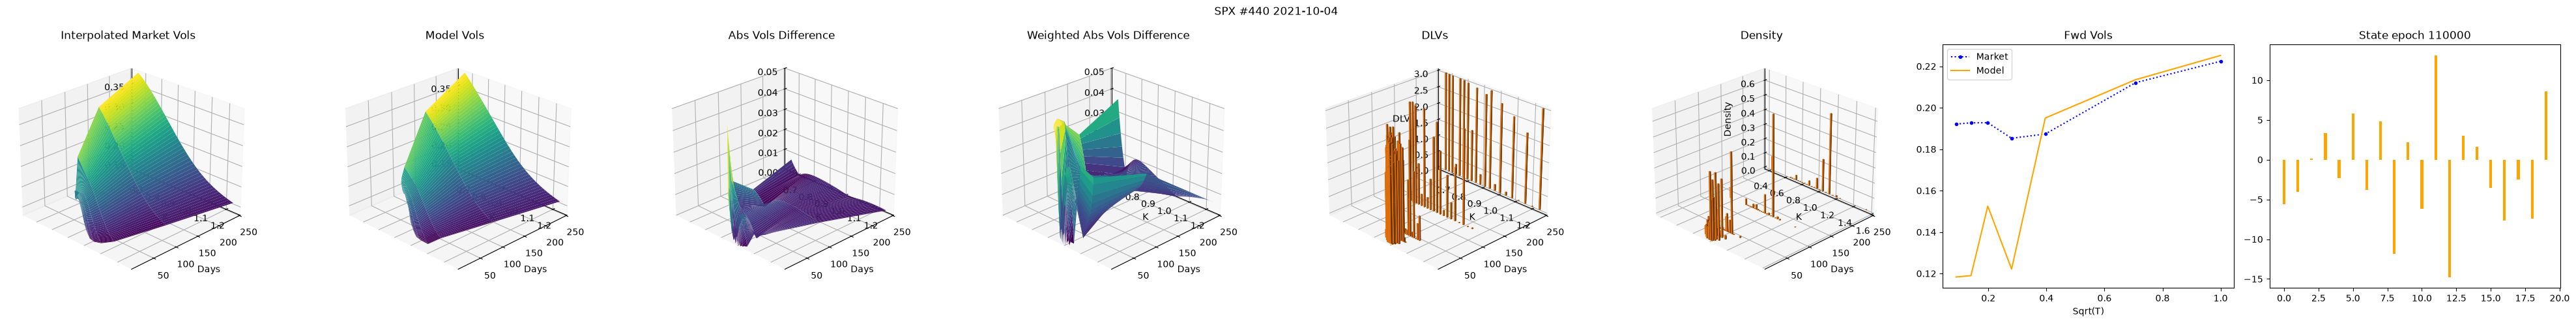

01:   Model checkpoint file is'/home/hans/.dysanos_grid/sm25_100/ac_state20 15353129.pt'.
01:   Writing model output to '/home/hans/.dysanos_grid/sm25_100/ac_state20 15353129.mo'... done; this took 0.011s.
00: Model ac_state20 version 0.2 group 'sm25_100' trained for 110000 epochs. Final training loss: 1.35e-06, valuation loss: 1.37e-06. This took 0.011s.
/done


In [7]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model import BaseEnvironment, FeedForward, SanosModel, SanosModelConfig, SanosDecoderConfig
import numpy as np

mdl_config = SanosModelConfig( 
    label="ac_state20",
    user_version="0.2",
    group="sm25_100",
    encoder_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    decoder_config = SanosDecoderConfig(
        smoothness = 0.25,
        num_state = 20, 
        nn_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    ),
)

viz_config = VizConfig( num_viz_dates=4 )
trn_config = TrainConfig( num_epochs=110_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-4, batch_size=400, compile=True, epoch_interval=10000 )
r, model, tdata = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config )
print("/done")